# Degree vs Cycle Rankings

This notebook collects the results for the topology-versus-degree ranking section. It is meant to make it easy to:

- inspect subject-averaged degree and cycle rankings by parcellation scale,
- verify score correlations and top-set overlap across scales,
- review the highest-ranked cycle-participation regions anatomically,
- reproduce the main rank-divergence figure for the manuscript.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/matplotlib')

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from IPython.display import display
from nilearn import datasets, plotting
from scipy.stats import spearmanr

REPO_ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from hoc.atlas import surface_values_from_node_scores

RESULTS_DIR = REPO_ROOT / 'results'
FIGURES_DIR = REPO_ROOT / 'figures' / 'section_degree_cycle_rankings'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ATLAS_DIR = REPO_ROOT / 'data' / 'external' / 'atlas_cache' / 'atl-cammoun2012' / 'fsaverage5'
FSAVERAGE = datasets.load_fsaverage(mesh='fsaverage5')

mpl.rcParams.update({
    'font.family': 'DejaVu Sans',
    'svg.fonttype': 'none',
    'axes.unicode_minus': False,
})

sns.set_theme(context='talk', style='whitegrid')

In [2]:
node_scores = pd.read_csv(RESULTS_DIR / 'primary' / 'node_scores.csv')
rank_divergence = pd.read_csv(RESULTS_DIR / 'primary' / 'rank_divergence.csv')
scales = [68, 114, 219]
TOP_N = 15

COLORS = {
    'degree_only': '#ef3b2c',
    'cycle_only': '#2b8cbe',
    'overlap': '#7b3294',
    'other': '#4d4d4d',
}
ANATOMICAL_ORDER = ['frontal', 'cingulate', 'insula', 'parietal', 'temporal', 'occipital', 'other']

## Helpers

In [3]:
def load_scale_data(scale: int) -> tuple[pd.DataFrame, np.ndarray]:
    labels = pd.read_csv(RESULTS_DIR / 'processed' / f'atlas_labels_scale-{scale}.csv')
    adjacency = np.load(RESULTS_DIR / 'processed' / f'connectomes_scale-{scale}.npz')['cohort_reference'].copy()
    np.fill_diagonal(adjacency, 0.0)
    return labels, adjacency


def mean_rank_table(scale: int) -> pd.DataFrame:
    subset = node_scores[
        (node_scores['scale'] == scale)
        & node_scores['method'].isin(['degree_strength', 'cycle_participation'])
    ].copy()
    means = (
        subset.groupby(
            ['node_index', 'region_label', 'base_region', 'hemi', 'anatomical_group', 'method'],
            as_index=False,
        )
        .agg(score=('score', 'mean'), mean_subject_rank=('rank', 'mean'))
    )
    wide = means.pivot_table(
        index=['node_index', 'region_label', 'base_region', 'hemi', 'anatomical_group'],
        columns='method',
        values=['score', 'mean_subject_rank'],
    )
    wide.columns = [f'{metric}_{method}' for metric, method in wide.columns]
    wide = wide.reset_index()
    wide['degree_rank'] = wide['score_degree_strength'].rank(ascending=False, method='min').astype(int)
    wide['cycle_rank'] = wide['score_cycle_participation'].rank(ascending=False, method='min').astype(int)
    wide['rank_delta_cycle_minus_degree'] = wide['cycle_rank'] - wide['degree_rank']
    wide['rank_delta_degree_minus_cycle'] = wide['degree_rank'] - wide['cycle_rank']
    return wide


def selected_categories(rank_table: pd.DataFrame) -> tuple[set[int], set[int], dict[int, str]]:
    degree_nodes = set(rank_table.nsmallest(TOP_N, 'degree_rank')['node_index'].astype(int))
    cycle_nodes = set(rank_table.nsmallest(TOP_N, 'cycle_rank')['node_index'].astype(int))
    categories = {}
    for node in rank_table['node_index'].astype(int):
        if node in degree_nodes and node in cycle_nodes:
            categories[node] = 'overlap'
        elif node in degree_nodes:
            categories[node] = 'degree_only'
        elif node in cycle_nodes:
            categories[node] = 'cycle_only'
        else:
            categories[node] = 'other'
    return degree_nodes, cycle_nodes, categories


def display_label(label: str) -> str:
    text = label.replace('_', ' ')
    replacements = {
        'lateralorbitofrontal': 'lateral orbitofrontal',
        'medialorbitofrontal': 'medial orbitofrontal',
        'rostralanteriorcingulate': 'rostral anterior cingulate',
        'caudalanteriorcingulate': 'caudal anterior cingulate',
        'postcentral': 'postcentral',
        'precentral': 'precentral',
        'superiorfrontal': 'superior frontal',
        'caudalmiddlefrontal': 'caudal middle frontal',
        'rostralmiddlefrontal': 'rostral middle frontal',
        'inferiorparietal': 'inferior parietal',
        'superiorparietal': 'superior parietal',
        'lateraloccipital': 'lateral occipital',
        'isthmuscingulate': 'isthmus cingulate',
        'posteriorcingulate': 'posterior cingulate',
        'parstriangularis': 'pars triangularis',
        'parsopercularis': 'pars opercularis',
        'parsorbitalis': 'pars orbitalis',
        'supramarginal': 'supramarginal',
        'precuneus': 'precuneus',
    }
    for old, new in replacements.items():
        text = text.replace(old, new)
    return text


def circular_order(labels: pd.DataFrame, rank_table: pd.DataFrame) -> list[int]:
    merged = labels.merge(rank_table[['node_index', 'degree_rank']], on='node_index', how='left')
    group_map = {name: idx for idx, name in enumerate(ANATOMICAL_ORDER)}
    merged['hemi_order'] = merged['hemi'].map({'L': 0, 'R': 1}).fillna(9)
    merged['group_order'] = merged['anatomical_group'].map(group_map).fillna(99)
    merged = merged.sort_values(['hemi_order', 'group_order', 'base_region', 'degree_rank', 'node_index'])
    return merged['node_index'].astype(int).tolist()

## Cross-scale summary

In [4]:
summary_rows = []
for scale in scales:
    rank_table = mean_rank_table(scale)
    score_rho, score_p = spearmanr(rank_table['score_degree_strength'], rank_table['score_cycle_participation'])
    rank_rho, rank_p = spearmanr(rank_table['mean_subject_rank_degree_strength'], rank_table['mean_subject_rank_cycle_participation'])
    degree_nodes, cycle_nodes, _ = selected_categories(rank_table)
    summary_rows.append({
        'scale': scale,
        'n_nodes': len(rank_table),
        'score_rho': score_rho,
        'score_p': score_p,
        'mean_rank_rho': rank_rho,
        'mean_rank_p': rank_p,
        'top15_overlap': len(degree_nodes & cycle_nodes),
        'top15_degree_only': len(degree_nodes - cycle_nodes),
        'top15_cycle_only': len(cycle_nodes - degree_nodes),
    })
summary_table = pd.DataFrame(summary_rows)
summary_table

,scale,n_nodes,score_rho,score_p,mean_rank_rho,mean_rank_p,top15_overlap,top15_degree_only,top15_cycle_only
0,68,68,0.750429,1.743980e-13,0.740614,5.238744e-13,11,4,4
1,114,114,0.706089,1.721491e-18,0.691671,1.595493e-17,4,11,11
2,219,219,0.611919,6.888374e-24,0.592796,3.595226e-22,5,10,10


In [5]:
summary_table_rounded = summary_table.copy()
summary_table_rounded['score_rho'] = summary_table_rounded['score_rho'].map(lambda x: f'{x:.2f}')
summary_table_rounded['score_p'] = summary_table_rounded['score_p'].map(lambda x: f'{x:.2e}')
summary_table_rounded['mean_rank_rho'] = summary_table_rounded['mean_rank_rho'].map(lambda x: f'{x:.2f}')
summary_table_rounded['mean_rank_p'] = summary_table_rounded['mean_rank_p'].map(lambda x: f'{x:.2e}')
summary_table_rounded

,scale,n_nodes,score_rho,score_p,mean_rank_rho,mean_rank_p,top15_overlap,top15_degree_only,top15_cycle_only
0,68,68,0.75,1.74e-13,0.74,5.24e-13,11,4,4
1,114,114,0.71,1.72e-18,0.69,1.60e-17,4,11,11
2,219,219,0.61,6.89e-24,0.59,3.60e-22,5,10,10


## Highest-ranked cycle-participation regions

In [6]:
rank_tables = {scale: mean_rank_table(scale) for scale in scales}
for scale in scales:
    print(f'\nScale {scale}')
    display(rank_tables[scale].nsmallest(15, 'cycle_rank')[['cycle_rank', 'region_label', 'anatomical_group', 'score_cycle_participation', 'score_degree_strength', 'degree_rank']])


Scale 68


,cycle_rank,region_label,anatomical_group,score_cycle_participation,score_degree_strength,degree_rank
41,1,R_superiorfrontal,frontal,0.725733,2.035578,3
51,2,R_superiorparietal,parietal,0.643080,1.038844,15
43,3,R_precentral,frontal,0.638105,1.251128,6
17,4,L_superiorparietal,parietal,0.629630,0.864801,22
9,5,L_precentral,frontal,0.605650,1.080761,14
7,6,L_superiorfrontal,frontal,0.600518,2.277480,1
53,7,R_precuneus,occipital,0.584028,1.116025,13
67,8,R_insula,insula,0.578456,1.245467,7
19,9,L_precuneus,occipital,0.566686,1.245429,8
56,10,R_lateraloccipital,occipital,0.496189,0.557653,40



Scale 114


,cycle_rank,region_label,anatomical_group,score_cycle_participation,score_degree_strength,degree_rank
70,1,R_superiorfrontal_4,frontal,0.678796,2.544649,1
112,2,R_insula_1,insula,0.668607,1.499914,10
88,3,R_inferiorparietal_2,parietal,0.650308,1.022171,33
71,4,R_caudalmiddlefrontal_1,frontal,0.632080,1.498455,11
29,5,L_superiorparietal_1,parietal,0.603367,0.936383,38
14,6,L_caudalmiddlefrontal_1,frontal,0.561276,1.357567,16
69,7,R_superiorfrontal_3,frontal,0.548030,1.628860,8
34,8,L_precuneus_1,occipital,0.534180,1.320758,21
92,9,R_cuneus_1,occipital,0.532861,0.987897,35
86,10,R_superiorparietal_3,parietal,0.490406,0.838324,46



Scale 219


,cycle_rank,region_label,anatomical_group,score_cycle_participation,score_degree_strength,degree_rank
29,1,L_precentral_1,frontal,0.669139,1.739797,15
136,2,R_superiorfrontal_7,frontal,0.662920,1.455835,28
216,3,R_insula_1,insula,0.606744,1.766650,13
130,4,R_superiorfrontal_1,frontal,0.579863,1.458031,27
23,5,L_superiorfrontal_7,frontal,0.573326,2.221482,6
118,6,R_medialorbitofrontal_2,frontal,0.572195,1.538790,23
215,7,R_transversetemporal_1,temporal,0.564160,1.124884,48
33,8,L_precentral_5,frontal,0.551885,1.013996,57
133,9,R_superiorfrontal_4,frontal,0.548018,1.481751,25
169,10,R_superiorparietal_6,parietal,0.540496,1.156466,46


In [7]:
group_rows = []
for scale in scales:
    top_cycle = rank_tables[scale].nsmallest(15, 'cycle_rank')
    counts = top_cycle['anatomical_group'].value_counts()
    for group, count in counts.items():
        group_rows.append({'scale': scale, 'anatomical_group': group, 'count_in_top15_cycle': count})
group_counts = pd.DataFrame(group_rows)
group_counts.pivot(index='anatomical_group', columns='scale', values='count_in_top15_cycle').fillna(0).astype(int)

scale,68,114,219
anatomical_group,,,
cingulate,2,0,0
frontal,5,5,9
insula,2,1,1
occipital,3,3,2
other,0,1,0
parietal,3,5,1
temporal,0,0,2


## Reproduce the main rank-divergence figure

In [8]:
def make_rank_divergence_figure(scale: int = 114, save: bool = True):
    labels, adjacency = load_scale_data(scale)
    rank_table = mean_rank_table(scale)
    degree_nodes, cycle_nodes, categories = selected_categories(rank_table)
    divergence = rank_table['rank_delta_degree_minus_cycle'].to_numpy()
    surface_scores = surface_values_from_node_scores(scale=scale, atlas_dir=ATLAS_DIR, node_scores=divergence)
    vmax = int(np.nanmax(np.abs(divergence)))
    rho, p_value = spearmanr(rank_table['score_degree_strength'], rank_table['score_cycle_participation'])
    selected_nodes = sorted(degree_nodes | cycle_nodes)
    order = [node for node in circular_order(labels, rank_table) if node in selected_nodes]
    angles = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, len(order), endpoint=False)
    positions = {node: np.array([np.cos(angle), np.sin(angle)]) for node, angle in zip(order, angles)}
    selected = np.array(order, dtype=int)
    sub_adj = adjacency[np.ix_(selected, selected)]
    upper = np.triu_indices_from(sub_adj, k=1)
    weights_all = sub_adj[upper]
    positive = np.where(weights_all > 0)[0]
    max_edges = min(len(positive), max(35, 3 * len(selected_nodes)))
    keep_local = positive[np.argsort(weights_all[positive])[-max_edges:]]
    edges = [
        (int(selected[upper[0][idx]]), int(selected[upper[1][idx]]), float(weights_all[idx]))
        for idx in keep_local
    ]
    weights = np.array([weight for _, _, weight in edges])
    norm = mpl.colors.Normalize(vmin=float(np.quantile(weights, 0.02)), vmax=float(np.quantile(weights, 0.995)))
    cmap = mpl.colormaps['jet']
    segments = [[positions[i], positions[j]] for i, j, _ in edges]
    fig = plt.figure(figsize=(15.8, 5.6), facecolor='black')
    gs = fig.add_gridspec(2, 3, width_ratios=[1.0, 1.05, 1.25], height_ratios=[1.0, 1.0], wspace=0.25, hspace=0.08)
    ax_heat_l = fig.add_subplot(gs[0, 0], projection='3d')
    ax_heat_r = fig.add_subplot(gs[1, 0], projection='3d')
    ax_scatter = fig.add_subplot(gs[:, 1])
    ax_graph = fig.add_subplot(gs[:, 2])
    plotting.plot_surf_stat_map(
        FSAVERAGE['inflated'].parts['left'], surface_scores['L'], hemi='left', view='lateral', cmap='coolwarm',
        colorbar=False, symmetric_cbar=True, vmax=vmax, axes=ax_heat_l, title=''
    )
    plotting.plot_surf_stat_map(
        FSAVERAGE['inflated'].parts['right'], surface_scores['R'], hemi='right', view='lateral', cmap='coolwarm',
        colorbar=False, symmetric_cbar=True, vmax=vmax, axes=ax_heat_r, title=''
    )
    for ax in (ax_heat_l, ax_heat_r):
        ax.set_title('')
        ax.set_facecolor('black')
    sm_heat = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=-vmax, vmax=vmax), cmap='coolwarm')
    cbar_heat = fig.colorbar(sm_heat, ax=[ax_heat_l, ax_heat_r], fraction=0.04, pad=0.03)
    cbar_heat.set_label('Degree rank - cycle rank', color='white', fontsize=11)
    cbar_heat.ax.tick_params(colors='white', labelsize=9)
    # ensure white background (override later black settings) on draw
    def _set_white_background(event):
        fig.patch.set_facecolor('white')
        for a in fig.axes:
            try:
                a.set_facecolor('white')
            except Exception:
                pass
            a.tick_params(colors='black')
            for spine in a.spines.values():
                spine.set_edgecolor('black')
            for t in a.texts:
                t.set_color('black')
        # adjust colorbars if present (they may be created later)
        try:
            cbar_heat.outline.set_edgecolor('black')
            cbar_heat.set_label('Degree rank - cycle rank', color='black', fontsize=11)
            cbar_heat.ax.tick_params(colors='black', labelsize=9)
        except Exception:
            pass
        try:
            cbar.outline.set_edgecolor('black')
            cbar.set_label('Weight', color='black', fontsize=11)
            cbar.ax.tick_params(colors='black', labelsize=9)
        except Exception:
            pass

    fig.canvas.mpl_connect('draw_event', _set_white_background)
    for cat in ['other', 'degree_only', 'cycle_only', 'overlap']:
        subset = rank_table[rank_table['node_index'].map(categories) == cat]
        ax_scatter.scatter(
            subset['score_degree_strength'],
            subset['score_cycle_participation'],
            s=22 if cat == 'other' else 58,
            c=COLORS[cat],
            edgecolors='white' if cat != 'other' else '#cccccc',
            linewidths=0.6,
            alpha=0.42 if cat == 'other' else 0.96,
        )
    ax_scatter.set_xlabel('Degree strength', color='white', fontsize=12)
    ax_scatter.set_ylabel('Cycle participation', color='white', fontsize=12)
    ax_scatter.tick_params(colors='white', labelsize=10)
    ax_scatter.grid(True, color='#666666', linewidth=0.6, alpha=0.35)
    ax_scatter.set_facecolor('black')
    for spine in ax_scatter.spines.values():
        spine.set_color('white')
    ax_scatter.text(
        0.04, 0.95, fr'$\rho = {rho:.2f}\quad p = {p_value:.1e}$',
        transform=ax_scatter.transAxes, ha='left', va='top', color='black', fontsize=11,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.92, pad=2.8),
    )
    edge_collection = LineCollection(
        segments,
        colors=cmap(norm(weights)),
        linewidths=0.18 + 1.25 * norm(weights),
        alpha=0.82,
        zorder=1,
    )
    ax_graph.add_collection(edge_collection)
    global_positive = adjacency[np.triu_indices_from(adjacency, k=1)]
    threshold = np.quantile(global_positive[global_positive > 0], 0.92)
    binary_degree = (adjacency >= threshold).sum(axis=1)
    sizes = [36 + 9.0 * np.sqrt(binary_degree[i]) for i in order]
    xy = np.array([positions[i] for i in order])
    node_colors = [COLORS[categories[i]] for i in order]
    ax_graph.scatter(xy[:, 0], xy[:, 1], s=sizes, c=node_colors, edgecolors='black', linewidths=0.6, zorder=3)
    for node in order:
        x, y = positions[node]
        label = display_label(str(labels.loc[node, 'region_label']))
        ha = 'left' if x >= 0 else 'right'
        ax_graph.text(1.11 * x, 1.11 * y, label, ha=ha, va='center', fontsize=6.0, color='black')
    ax_graph.set_xlim(-1.24, 1.24)
    ax_graph.set_ylim(-1.24, 1.24)
    ax_graph.set_aspect('equal')
    ax_graph.axis('off')
    ax_graph.set_facecolor('black')
    legend_handles = [
        Line2D([0], [0], marker='o', color='none', markerfacecolor=COLORS['degree_only'], markeredgecolor='black', markersize=8, label='Degree only'),
        Line2D([0], [0], marker='o', color='none', markerfacecolor=COLORS['cycle_only'], markeredgecolor='black', markersize=8, label='Cycle only'),
        Line2D([0], [0], marker='o', color='none', markerfacecolor=COLORS['overlap'], markeredgecolor='black', markersize=8, label='Overlap'),
    ]
    leg = ax_graph.legend(handles=legend_handles, frameon=False, fontsize=9, loc='lower center', bbox_to_anchor=(0.5, -0.08), ncol=3)
    for text in leg.get_texts():
        text.set_color('black')
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    cbar = fig.colorbar(sm, ax=ax_graph, fraction=0.046, pad=0.02)
    cbar.set_label('Weight', color='black', fontsize=11)
    cbar.ax.tick_params(colors='black', labelsize=9)
    cbar.outline.set_edgecolor('white')
    if save:
        out = FIGURES_DIR / f'rank_divergence_scale{scale}_combined_dark.svg'
        fig.savefig(out, bbox_inches='tight')
        print(out)
    return fig

/opt/anaconda3/lib/python3.12/site-packages/mpl_toolkits/mplot3d/art3d.py:1403: RuntimeWarning: divide by zero encountered in matmul
  shade = ((normals / np.linalg.norm(normals, axis=1, keepdims=True))
/opt/anaconda3/lib/python3.12/site-packages/mpl_toolkits/mplot3d/art3d.py:1403: RuntimeWarning: overflow encountered in matmul
  shade = ((normals / np.linalg.norm(normals, axis=1, keepdims=True))


/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_degree_cycle_rankings/rank_divergence_scale219_combined_dark.svg


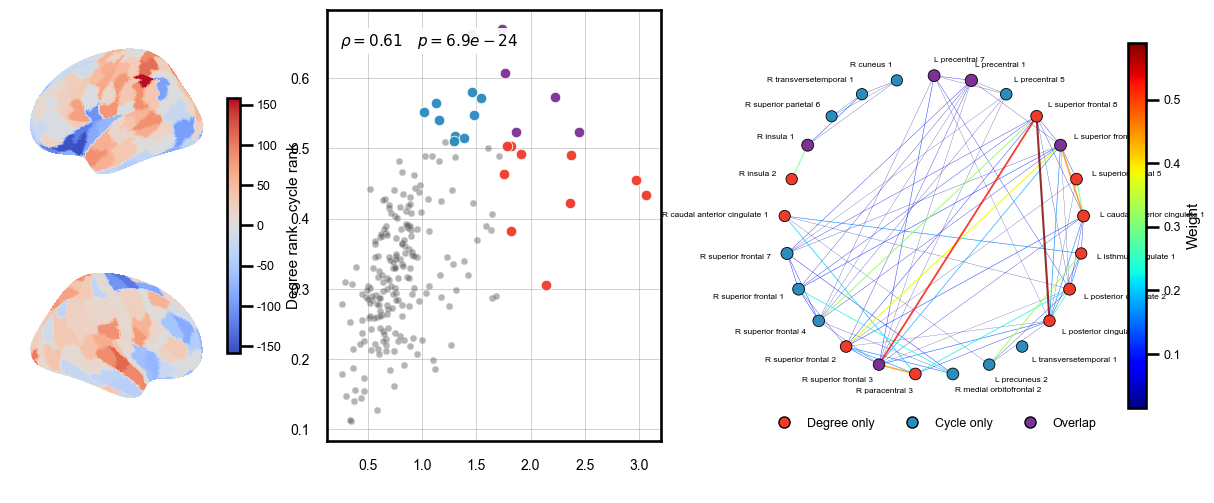

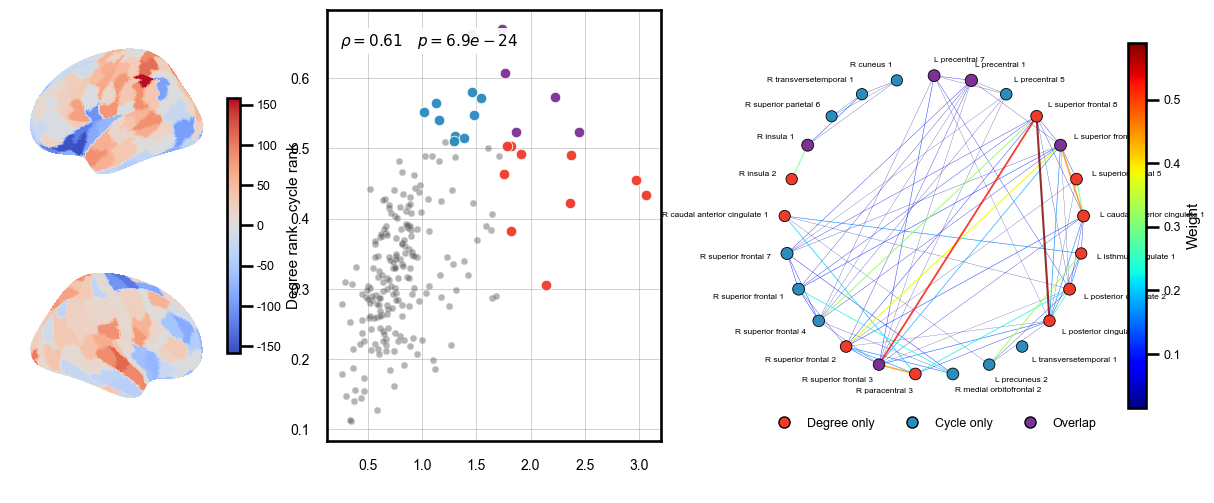

In [9]:
# Change scale as needed (68, 114, or 219)
fig = make_rank_divergence_figure(scale=219, save=True)
fig

## Optional: regenerate the separate panel files for all scales

In [10]:
summary_table[['scale', 'score_rho', 'score_p', 'top15_overlap']]

,scale,score_rho,score_p,top15_overlap
0,68,0.750429,1.743980e-13,11
1,114,0.706089,1.721491e-18,4
2,219,0.611919,6.888374e-24,5
